In [15]:
%pip install scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [17]:
data = pd.read_csv("advertising.csv")

df = pd.DataFrame(data)

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [18]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Shape: (200, 4)

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


In [19]:
print("Columns:")
print(df.columns)

Columns:
Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')


In [20]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("X:")
print(X)

print("\ny:")
print(y)

X:
        TV  Radio  Newspaper
0    230.1   37.8       69.2
1     44.5   39.3       45.1
2     17.2   45.9       69.3
3    151.5   41.3       58.5
4    180.8   10.8       58.4
..     ...    ...        ...
195   38.2    3.7       13.8
196   94.2    4.9        8.1
197  177.0    9.3        6.4
198  283.6   42.0       66.2
199  232.1    8.6        8.7

[200 rows x 3 columns]

y:
0      22.1
1      10.4
2      12.0
3      16.5
4      17.9
       ... 
195     7.6
196    14.0
197    14.8
198    25.5
199    18.4
Name: Sales, Length: 200, dtype: float64


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (160, 3)
X_test shape: (40, 3)
y_train shape: (160,)
y_test shape: (40,)


In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.05,0.1 ,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.714
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [23]:
print("Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print("\nIntercept:", model.intercept_)

Coefficients:
TV: 0.0545
Radio: 0.1009
Newspaper: 0.0043

Intercept: 4.714126402214127


In [24]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

comparison

,Actual Sales,Predicted Sales
0,16.9,17.034772
1,22.4,20.409740
2,21.4,23.723989
3,7.3,9.272785
4,24.7,21.682719
5,12.6,12.569402
6,22.3,21.081195
7,8.4,8.690350
8,16.5,17.237013
9,16.1,16.666575


In [25]:
# New advertising budget
new_advertising = pd.DataFrame({
    "TV": [150],
    "Radio": [20],
    "Newspaper": [30]
})

# Predict sales
predicted_sales = model.predict(new_advertising)

print("Predicted Sales:", predicted_sales[0])

Predicted Sales: 15.039523680317231


For an advertising budget of TV = 150, Radio = 20, and Newspaper = 30, the trained Multiple Linear Regression model predicts approximately 15.04 units of sales.

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# 2. Root Mean Squared Error
rmse = np.sqrt(mse)

# 3. Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

# 4. R² Score
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("Mean Absolute Error (MAE):", mae)
print("R² Score:", r2)

Mean Squared Error (MSE): 2.9077569102710896
Root Mean Squared Error (RMSE): 1.7052146229349223
Mean Absolute Error (MAE): 1.2748262109549338
R² Score: 0.9059011844150826


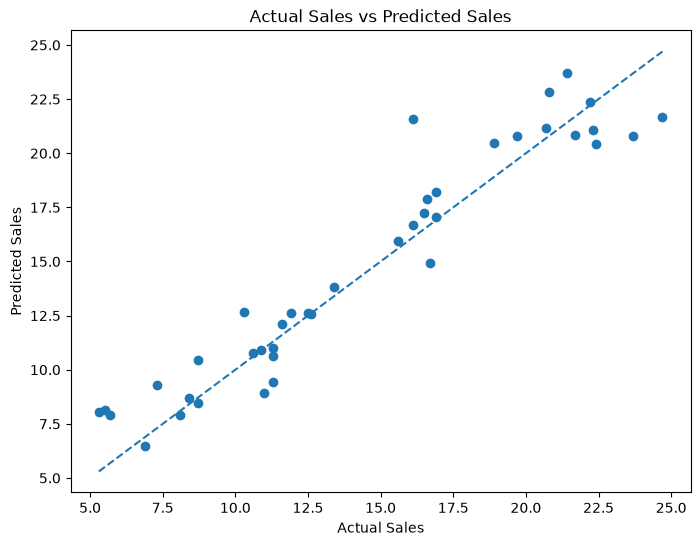

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

Interpretation: The actual and predicted sales values show a strong positive relationship. Most observations are located reasonably close to the reference line, indicating that the Multiple Linear Regression model provides a good prediction of sales, although some observations have noticeable prediction errors.

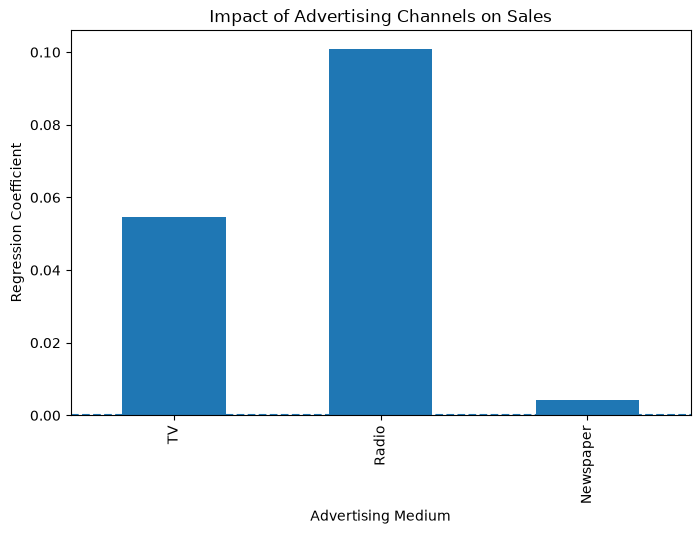

In [28]:
coefficients = pd.Series(
    model.coef_,
    index=X.columns
)

plt.figure(figsize=(8, 5))

coefficients.plot(kind="bar")

plt.xlabel("Advertising Medium")
plt.ylabel("Regression Coefficient")
plt.title("Impact of Advertising Channels on Sales")

plt.axhline(0, linestyle="--")

plt.show()

"According to our Multiple Linear Regression model, Radio has the strongest estimated positive impact on Sales, while Newspaper has the weakest estimated impact, holding the other advertising channels constant."

# Advertising Sales Prediction Using Multiple Linear Regression

## 1. Business Scenario

A consumer goods company promotes its products through multiple advertising channels:

- Television (TV)
- Radio
- Newspaper

The company wants to understand how advertising expenditure across these channels influences product sales. It also wants to predict future sales based on a planned advertising budget.

As a Data Analyst, the objective is to analyze the historical advertising data and develop a machine learning model that can predict product sales.

---

## 2. Business Problem

The main business questions are:

1. How do TV, Radio, and Newspaper advertising expenditures influence Sales?
2. Can we build a model to predict Sales using these advertising channels?
3. What will be the expected Sales for a planned advertising budget?
4. Which advertising medium has the strongest impact on Sales?
5. Which advertising medium has the least impact?
6. How accurate is the prediction model?

---

## 3. Dataset

The Advertising dataset contains historical information about advertising expenditure and product sales.

### Features

- **TV** – Advertising expenditure through television
- **Radio** – Advertising expenditure through radio
- **Newspaper** – Advertising expenditure through newspapers

### Target Variable

- **Sales** – Product sales generated from the advertising expenditure

The dataset contains **200 records and 4 columns**.

There are no missing values in the dataset, and all variables are numerical.

---

## 4. Machine Learning Approach

Since Sales is a continuous numerical variable and there are multiple input features, **Multiple Linear Regression** is used.

The model learns the relationship between the three advertising channels and Sales.

The general equation is:

**Sales = Intercept + β₁(TV) + β₂(Radio) + β₃(Newspaper)**

where:

- β₁ represents the effect of TV advertising
- β₂ represents the effect of Radio advertising
- β₃ represents the effect of Newspaper advertising

---

## 5. Project Workflow

The analysis follows these steps:

1. Import the required Python libraries
2. Load the Advertising dataset
3. Examine the dataset structure
4. Check the shape, columns, data types, and missing values
5. Define the input features (X) and target variable (y)
6. Split the dataset into training and testing data
7. Build the Multiple Linear Regression model
8. Train the model using historical data
9. Analyze the model coefficients and intercept
10. Predict Sales for unseen test data
11. Predict Sales for a new advertising budget
12. Evaluate the model using regression metrics
13. Visualize Actual Sales vs Predicted Sales
14. Visualize the impact of each advertising channel
15. Provide business and technical recommendations

---

## 6. Train-Test Split

The dataset is divided into:

- **80% training data** – used to train the model
- **20% testing data** – used to evaluate the model on unseen data

A `random_state` is used so that the same train-test split can be reproduced.

---

## 7. Model Results

The trained Multiple Linear Regression model produced the following coefficients:

| Advertising Medium | Coefficient |
|--------------------|------------:|
| TV | 0.0545 |
| Radio | 0.1009 |
| Newspaper | 0.0043 |

Intercept:

**4.7141**

The learned regression equation is approximately:

**Sales = 4.7141 + 0.0545(TV) + 0.1009(Radio) + 0.0043(Newspaper)**

---

## 8. Coefficient Interpretation

The coefficients represent the estimated change in Sales when one advertising variable increases by one unit, while the other advertising variables are kept constant.

- **Radio** has the highest coefficient (0.1009), indicating the strongest estimated positive impact on Sales.
- **TV** has the second-highest coefficient (0.0545).
- **Newspaper** has the smallest coefficient (0.0043), indicating the weakest estimated impact.

Therefore:

**Strongest impact → Radio**

**Least impact → Newspaper**

---

## 9. Sales Prediction for Planned Advertising Budget

The trained model was used to predict Sales for the following advertising budget:

- TV = 150
- Radio = 20
- Newspaper = 30

The predicted Sales is:

**15.0395 ≈ 15.04 units**

Therefore, for the planned advertising budget, the model predicts approximately **15.04 units of Sales**.

---

## 10. Model Evaluation

The model was evaluated using four regression metrics:

| Metric | Value |
|--------|------:|
| Mean Squared Error (MSE) | 2.9078 |
| Root Mean Squared Error (RMSE) | 1.7052 |
| Mean Absolute Error (MAE) | 1.2748 |
| R² Score | 0.9059 |

### Interpretation

- **MAE = 1.2748:** On average, the model's predictions differ from the actual Sales by approximately 1.27 units.
- **RMSE = 1.7052:** The typical prediction error is approximately 1.71 Sales units, with larger errors receiving greater influence.
- **MSE = 2.9078:** Represents the average squared prediction error.
- **R² = 0.9059:** The model explains approximately **90.59% of the variation in Sales** in the test dataset.

Overall, the model demonstrates a strong predictive relationship between advertising expenditure and Sales.

---

## 11. Visual Analysis

Two visualizations are used in this analysis:

### Actual Sales vs Predicted Sales

This scatter plot compares the actual Sales values with the Sales predicted by the model.

Points closer to the reference line indicate more accurate predictions.

### Advertising Channel Coefficients

A coefficient bar chart is used to compare the estimated impact of TV, Radio, and Newspaper advertising on Sales.

The visualization shows that Radio has the highest coefficient, while Newspaper has the lowest.

---

## 12. Business Recommendation

The company should consider prioritizing **Radio advertising** because it has the highest estimated positive coefficient in the regression model.

However, the final advertising budget should also consider factors such as advertising cost, audience reach, campaign performance, and return on investment.

---

## 13. Technical Recommendation

To improve prediction accuracy and model reliability, **cross-validation** can be used instead of relying on a single train-test split.

Other regression techniques such as Ridge Regression, Lasso Regression, and Polynomial Regression can also be compared with the current model to determine whether they provide better generalization on unseen data.

---

## 14. Conclusion

A Multiple Linear Regression model was successfully developed to analyze the relationship between advertising expenditure and product Sales.

The model used TV, Radio, and Newspaper advertising expenditure as input features and Sales as the target variable.

The model achieved an **R² score of 0.9059**, indicating that it explains approximately **90.59% of the variation in Sales** in the test dataset.

Among the three advertising channels, **Radio showed the strongest estimated impact on Sales**, while **Newspaper showed the weakest estimated impact**.

For an advertising budget of **TV = 150, Radio = 20, and Newspaper = 30**, the model predicted approximately **15.04 units of Sales**.

The analysis demonstrates how Multiple Linear Regression can be used to support advertising and sales-related business decisions.